In [305]:
import sys
import pathlib
import xarray
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
import astropy.io.fits
import dask.array
import tqdm
import pandas
import warnings
from astropy.wcs import FITSFixedWarning

from astropy.visualization import AsymmetricPercentileInterval, ImageNormalize,LogStretch
from sunpy.coordinates import get_earth, Helioprojective
from astropy.coordinates import SkyCoord

from mocksipipeline.instrument.configuration import moxsi_built_spectrogram_slot, moxsi_cdr_spectrogram_pinhole, moxsi_built_filtergrams

# sys.path.append('../pedestal/')
# from build_zarr_dataset import list_of_files_to_ds

In [2]:
data_root_dir = pathlib.Path('../../calibration_data_sandbox/')

In [3]:
MOXSI_DETECTOR_SHAPE = (2000, 1504)


def _steinharthart(coeff, scale=False):
    # scale=True is for "det0", which is the detector temperature
    def func(dn):
        r = dn / (4096 - dn)
        if scale:
            r *= 10000
        result = 1 / np.poly1d(coeff[::-1])(np.log(r)) - 273.15
        return result
    return func


# These are the Steinhart-Hart functions, which we will use
det0temp_sh = _steinharthart([1.1292E-03, 2.3411E-04, 0.0000E+00, 8.7755E-08], scale=True)
det1temp_sh = _steinharthart([3.3540E-03, 2.5708E-04, 1.8939E-06, 1.8973E-07])
fpgatemp_sh = _steinharthart([3.3540E-03, 2.5708E-04, 1.8939E-06, 1.8973E-07])
thermadc_sh = _steinharthart([3.3540E-03, 3.0013E-04, 5.0852E-06, 2.1877E-07])


def _read_fits_image(filename):
    with astropy.io.fits.open(filename, memmap=False) as hdul:
        image = hdul[0].data[:MOXSI_DETECTOR_SHAPE[0], :MOXSI_DETECTOR_SHAPE[1]]
        # Copy so the returned array remains valid after the FITS file closes.
        return np.array(image, copy=True)[:,:]


def list_of_files_to_ds_lazy(filenames):
    """
    Transform a list of MOXSI FITS files to a single xarray DataSet

    Parameters
    ----------
    filenames
    """
    # Build dataset
    meta_keys = [
        'DET0TEMP', 'DET1TEMP', 'THERMADC', 'FPGATEMP', 'EXPTIME', 'DATE', 'FRAME_ID'
    ]
    meta_arrays = {k: [] for k in meta_keys}
    # data = np.empty((len(filenames),)+MOXSI_DETECTOR_SHAPE)
    frames = []
    for i, filename in enumerate(tqdm.tqdm(filenames)):
        with astropy.io.fits.open(filename, memmap=False) as hdul:
            _header = hdul[0].header
            image_dtype = hdul[0].data.dtype
            #data[i,...] = hdul[0].data[:MOXSI_DETECTOR_SHAPE[0], :MOXSI_DETECTOR_SHAPE[1]]
        # NOTE: This avoids having to read in the whole array into memory
        frames.append(dask.array.from_delayed(
            dask.delayed(_read_fits_image)(filename),
            shape=MOXSI_DETECTOR_SHAPE,
            dtype=image_dtype,
        ))
        for k in meta_arrays.keys():
            meta_arrays[k].append(_header[k])
    data = dask.array.stack(frames, axis=0)
    #data = dask.array.from_array(
    #    data,
    #    chunks=(None, 100, 100),
    #)
    time_coord = pandas.to_datetime(meta_arrays['DATE'])
    ds = xarray.Dataset(
        {'data': (["sample", "row", "column"], data),},
        coords={
            "time": (["sample"], time_coord),
            "frame_id": (["sample"], np.array(meta_arrays['FRAME_ID'])),
            'temperature_detector_0': (["sample"], np.array(meta_arrays['DET0TEMP'])),
            'temperature_detector_1': (["sample"], np.array(meta_arrays['DET1TEMP'])),
            'temperature_adc': (["sample"], np.array(meta_arrays['THERMADC'])),
            'temperature_fpga': (["sample"], np.array(meta_arrays['FPGATEMP'])),
            'exposure_time': (["sample"], np.array(meta_arrays['EXPTIME'])),
        }
    )
    # Apply conversion functions for temperature
    ds['temperature_detector_0'].data = det0temp_sh(ds['temperature_detector_0'])
    ds['temperature_detector_1'].data = det1temp_sh(ds['temperature_detector_1'])
    ds['temperature_adc'].data = thermadc_sh(ds['temperature_adc'])
    ds['temperature_fpga'].data = fpgatemp_sh(ds['temperature_fpga'])
    # Add unit information
    ds['data'].attrs['unit'] = 'DN'
    for k in ['detector_0', 'detector_1', 'adc', 'fpga']:
        ds[f'temperature_{k}'].attrs['unit'] = 'deg C'
    ds['exposure_time'].attrs['unit'] = 'ms'
    return ds


In [4]:
def get_offset_from_zeroth_order(wavelength):
    earth_observer = get_earth('2020-01-01')
    ref_coord = SkyCoord(0, 0, unit='arcsec', frame=Helioprojective(observer=earth_observer))
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        px_0 = moxsi_built_spectrogram_slot[11].get_wcs(earth_observer).world_to_pixel(ref_coord, 1*u.AA)[0]
        offsets = []
        orders = []
        for channel in moxsi_built_spectrogram_slot[:11] + moxsi_built_spectrogram_slot[12:]:
            px = channel.get_wcs(earth_observer).world_to_pixel(ref_coord, wavelength)[0]
            offsets.append(px-px_0)
            orders.append(channel.spectral_order)
    return np.array(orders), np.array(offsets)

In [47]:
def plot_summed_slot_spectra(ds,
                             wavelengths,
                             max_order=11,
                             slot_slice=np.s_[1250:1350],
                             nudge0=0, 
                             text_ypos=3e6, 
                             ylim=(5e3,1e8), 
                             xlim=(0,2000)):
    """
    Plot summed spectra over the MXOSI slot, labeling any lines as needed.
    """
    plt.figure(figsize=(18,6))
    sum_spec = ds.sel(column=slot_slice).sum(dim='column')
    sum_spec.plot(color='k')
    p0_abs = np.argmax(sum_spec.data) + nudge0
    plt.axvline(x=p0_abs, color='k', ls='--')
    plt.yscale('log')
    for i,w in enumerate(wavelengths):
        so,dx = get_offset_from_zeroth_order(w)
        labeled = False
        for j,(_s,_d) in enumerate(zip(so,dx)):
            if abs(_s)>max_order:
                continue
            plt.axvline(x=p0_abs+_d, ls=':',color=f'C{i}', label=w if not labeled else None)
            labeled = True
            if (p0_abs+_d) < xlim[1] and (p0_abs+_d) > xlim[0]:
                plt.text(p0_abs+_d,text_ypos,_s,ha='center',va='center',color=f'C{i}')
    plt.ylim(*ylim)
    plt.xlim(*xlim)
    plt.legend()

This is a pedestal removal from our 6 parameter model.

In [48]:
def pedestal_func(ds, coeffs):
    t_det0 = ds.temperature_detector_0
    exposure = ds.exposure_time
    t_adc = ds.temperature_adc
    # All test models have a and f terms
    return (coeffs.sel(param='a')
            + coeffs.sel(param='f') * t_adc
            + coeffs.sel(param='b') * exposure * np.exp(t_det0 / coeffs.sel(param='c'))
            + coeffs.sel(param='d') * t_det0
            + coeffs.sel(param='e') * t_det0**2)

In [7]:
def pedestal_remove_median_short(ds):
    return ds['data'] - get_short_dark(ds)


def get_short_dark(ds):
    return ds.isel(
        sample=np.where(ds.exposure_time<=200)[0]
    )['data'].median(
        dim='sample'
    ).compute()

In [86]:
def build_per_exposure_dark_model(file_list):
    ds_dark_frames = list_of_files_to_ds_lazy(file_list)
    dark_model_per_exp_time = {}
    for exp_time in np.unique(ds_dark_frames.exposure_time):
        dark_model_per_exp_time[exp_time] = ds_dark_frames['data'].sel(exposure_time=exp_time).median(dim='sample')
    return dark_model_per_exp_time

In [87]:
def pedestal_remove_dark_frames(ds, dark_model):
    dark_stack = xarray.concat([dark_model[k] for k in ds.exposure_time.data], dim='sample')
    return ds['data'] - dark_stack

## Load table of relevant spectral lines

In [8]:
psa_target_table = astropy.table.Table.from_pandas(pandas.read_csv('/Users/wtbarnes/Downloads/Calibration targets - GSFC Targets (1).csv'))[17:]
new_table = {'Element': [], 'Z': [], 'Wavelength': []}
colnames = psa_target_table.colnames
for row in psa_target_table:
    el = row[colnames[0]]
    Z = int(row[colnames[1]])
    for cname in colnames[2:]:
        if not isinstance(row[cname], np.ma.core.MaskedConstant):
            new_table['Element'].append(el)
            new_table['Z'].append(Z)
            new_table['Wavelength'].append(float(row[cname]))
psa_target_table = astropy.table.QTable(new_table)
psa_target_table['Wavelength'].unit = u.AA
psa_target_table['Energy'] = psa_target_table['Wavelength'].to('keV', equivalencies=u.spectral())

In [9]:
for mr in moxsi_built_spectrogram_slot[12:16]:
    psa_target_table.add_column(
        np.interp(psa_target_table['Wavelength'],mr.wavelength, mr.wavelength_response,left=np.nan,right=np.nan),
        name=f'EA order={mr.spectral_order}'
    )

/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),
/Users/wtb

In [10]:
psa_target_table.pprint_all()

Element  Z  Wavelength        Energy             EA order=1             EA order=2             EA order=3             EA order=4      
             Angstrom          keV              cm2 DN / ph            cm2 DN / ph            cm2 DN / ph            cm2 DN / ph      
------- --- ---------- ------------------- ---------------------- ---------------------- ---------------------- ----------------------
      C   6      44.73 0.27718354221596303 0.00015229408169069498                    nan                    nan                    nan
      O   8       23.6  0.5253567730220349 0.00027103844433618116  5.069237478693991e-05 1.2781203083030444e-05                    nan
     Al  13       8.32  1.4901946927067333   0.008123060946746427  0.0009596238889302692  0.0006770315695891335  0.0004219528261768271
     Al  13       7.94  1.5615138341712878   0.008420456838549781  0.0009095021982393029  0.0006868981720001937   0.000401737320623012
     Ti  22       2.75   4.508516306661827   0.02077814

This is comparing expected DN for the tungsten and Cu Lalpha lines. They look very similar here, though not in the data.

In [11]:
(3000*u.ph/u.s/(u.cm**2)/u.milliampere * (2*u.h) * (100*u.milliampere) * psa_target_table[14]['EA order=1']).to('DN')

<Quantity 4595384.30671268 DN>

In [12]:
(700*u.ph/u.s/(u.cm**2)/u.milliampere * (2*u.h) * (100*u.milliampere) * psa_target_table[-1]['EA order=1']).to('DN')

<Quantity 4686004.29060923 DN>

/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/astropy/units/equivalencies.py:162: RuntimeWarning: divide by zero encountered in divide
  (si.m, si.J, lambda x: hc / x),


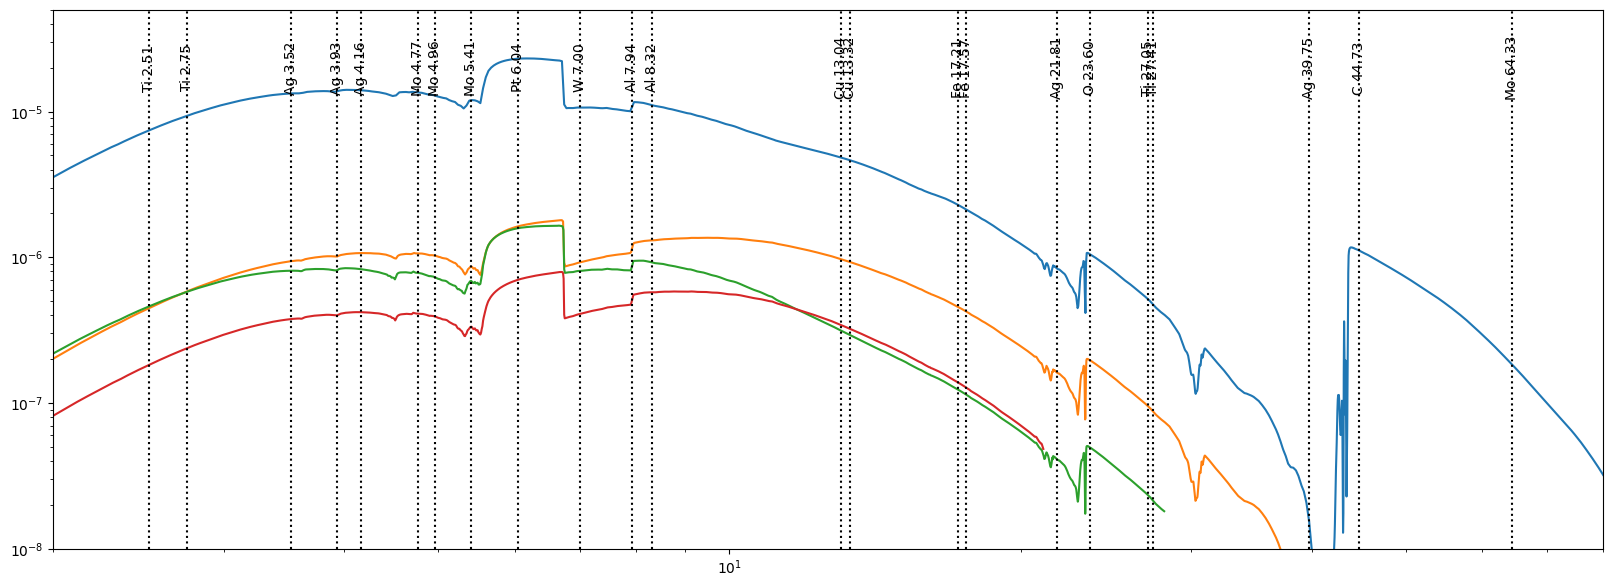

In [13]:
fig = plt.figure(figsize=(20,7))
ax = fig.add_subplot()
xlim = [2,80]*u.AA
for mr in moxsi_built_spectrogram_slot[12:16]:
    ax.plot(mr.wavelength, mr.effective_area)
for row in psa_target_table:
    if row['Wavelength']>xlim[0] and row['Wavelength']<xlim[1]:
        ax.axvline(x=row['Wavelength'].to_value('AA'), ls=':', color='k')
        ax.text(row['Wavelength'].to_value('AA'), 2e-5, f'{row['Element']} {row['Wavelength'].to_value('AA'):.2f}', rotation=90, va='center', ha='center', color='k')
ax.set_yscale('log')
ax.set_ylim(1e-8, 5e-5)
ax.set_xlim(*xlim.to_value('AA'))
ax.set_xscale('log')

## Dark model from dark frames
9:02 to 9:38 should be dark without any LED

- median of per-exposure time darks
- have a dark model that does a look up on exposure time
- subtract off

In [72]:
dark_frames_20261103 = sorted((data_root_dir / '20261103' / 'dark_frames').glob('csie_image*.bin.fits'))[14:]
ds_dark_frames_20261103 = build_per_exposure_dark_model(dark_frames_20261103)
dark_frames_20261104 = sorted((data_root_dir / '20261104' / 'dark_frames').glob('csie_image*.bin.fits'))
ds_dark_frames_20261104 = build_per_exposure_dark_model(dark_frames_20261104)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 138/138 [00:00<00:00, 194.52it/s]


## TVAC Fitted Pedestal Model

In [102]:
ped_coeffs = xarray.open_dataarray(data_root_dir / 'fit_coefficients_tvac.nc')

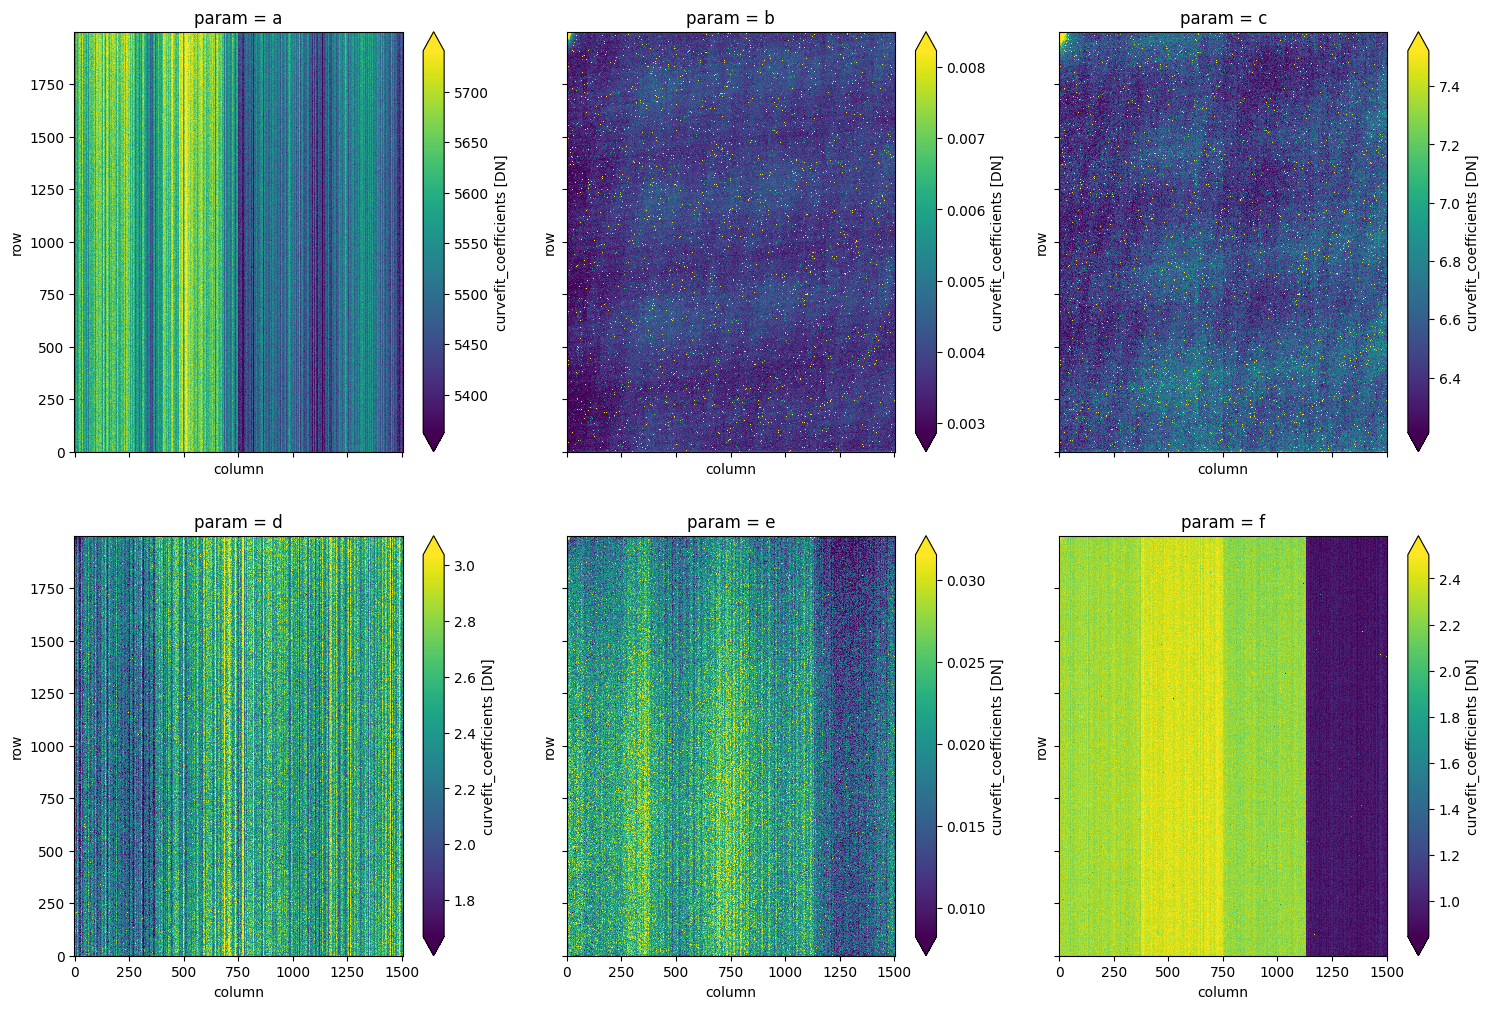

In [58]:
size = 6 
fig,axes = plt.subplots(2,3,figsize=(size*3,size*2),sharex=True,sharey=True)
for i,ax in enumerate(axes.flatten()):
    vmin, vmax = AsymmetricPercentileInterval(1,99).get_limits(ped_coeffs[...,i].data)
    ped_coeffs[...,i].plot.imshow(ax=ax, vmin=max(0,vmin), vmax=vmax)

## Fe Target

In [17]:
fe_target_files = sorted((data_root_dir / '20261102').glob('csie_image_*.bin.fits'))#[500:600]
# Change in pointing at approimxately 11:39 EST/17:39 UTC
pointing_changes = np.array(['2026-11-02T16:39:00', '2026-11-02T18:13'], dtype='datetime64[us]')
# Change in pointing at approximately 13:13 EST/18:13 UTC
#fe_target_files_p0 = fe_target_files
#fe_target_files_p1 = fe_target_files[:-231]
#fe_target_files_p2 = fe_target_files[-231:]

In [18]:
ds_fe = list_of_files_to_ds_lazy(fe_target_files)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1203/1203 [00:05<00:00, 217.54it/s]


In [22]:
#fe_target_wavelengths = np.append(psa_target_table[psa_target_table['Element']=='Fe']['Wavelength'], 7*u.AA)
fe_target_wavelengths = ([.7185,.705,1.773,6.391,7.058,]*u.keV).to('AA', equivalencies=u.spectral())

### Pointing 0

In [19]:
ds_fe_p0 = ds_fe.isel(sample=np.where(ds_fe.time<pointing_changes[0])[0])

In [20]:
ds_fe_p0_sub = pedestal_remove_dark_frames(ds_fe_p0.sel(exposure_time=60000))

In [21]:
ds_fe_p0_sub_sum = ds_fe_p0_sub.sum(dim='sample').compute()

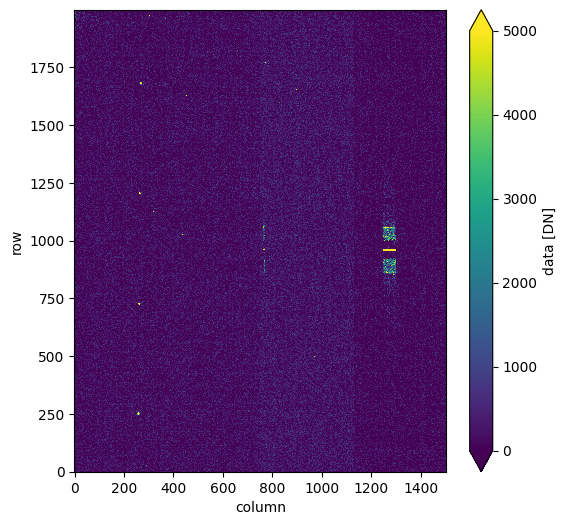

In [27]:
size=6
fig = plt.figure(figsize=(size,size))
ax = fig.add_subplot()
norm = ImageNormalize(vmin=0,vmax=5e3)
ds_fe_p0_sub_sum.plot.imshow(ax=ax, cmap='viridis',norm=norm,interpolation='none')#vmin=2.8e6, vmax=3.1e6,cmap='viridis');

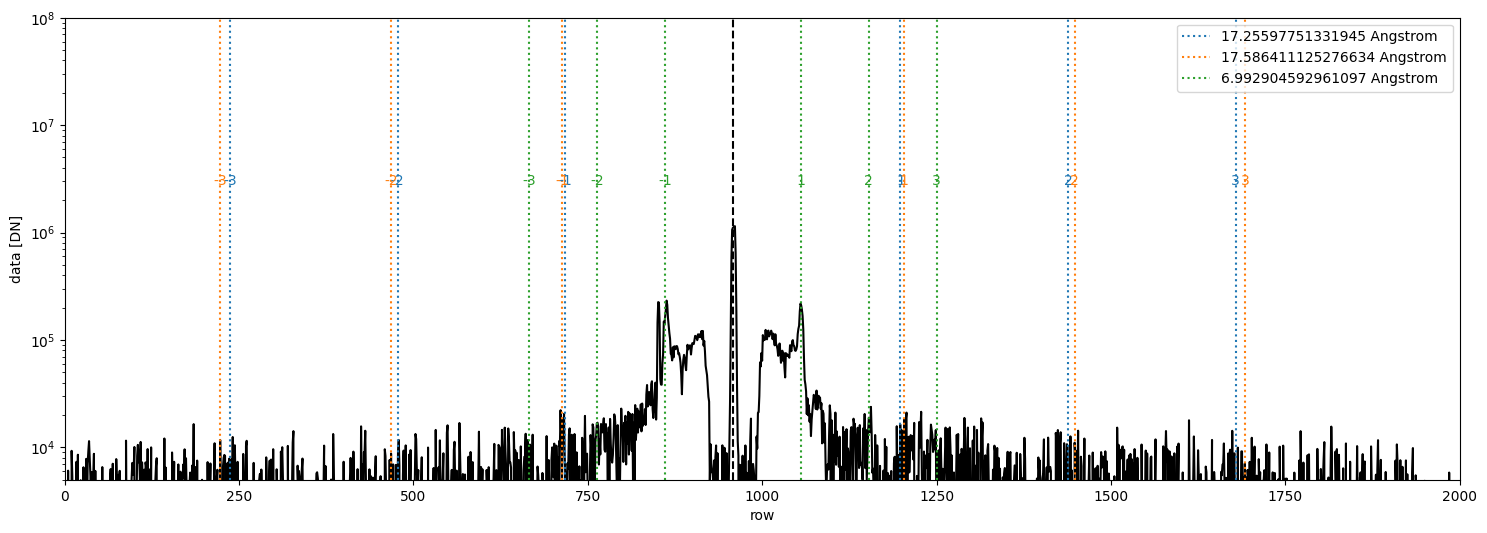

In [33]:
plot_summed_slot_spectra(ds_fe_p0_sub_sum, fe_target_wavelengths[:3], max_order=3, nudge0=-3)

### Pointing 1

In [42]:
ds_fe_p1 = ds_fe.isel(sample=np.where(np.logical_and(ds_fe.time>pointing_changes[0], ds_fe.time<pointing_changes[1]))[0])

In [43]:
ds_fe_p1_sub = pedestal_remove_dark_frames(ds_fe_p1.sel(exposure_time=60000))

In [44]:
ds_fe_p1_sub_sum = ds_fe_p1_sub.sum(dim='sample').compute()

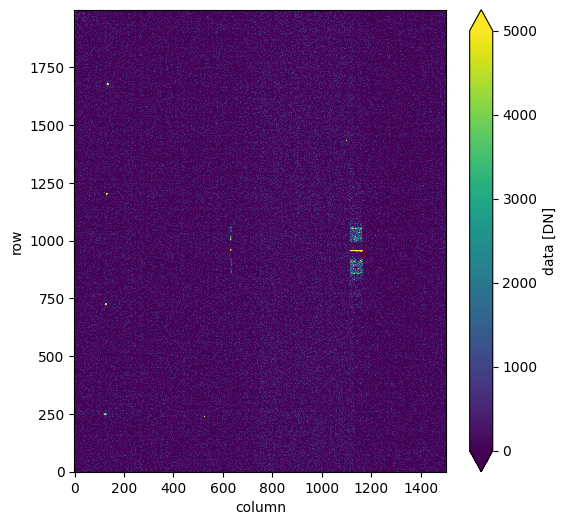

In [45]:
size=6
fig = plt.figure(figsize=(size,size))
ax = fig.add_subplot()
norm = ImageNormalize(vmin=0,vmax=5e3)
ds_fe_p1_sub_sum.plot.imshow(ax=ax, cmap='viridis',norm=norm,interpolation='none')#vmin=2.8e6, vmax=3.1e6,cmap='viridis');

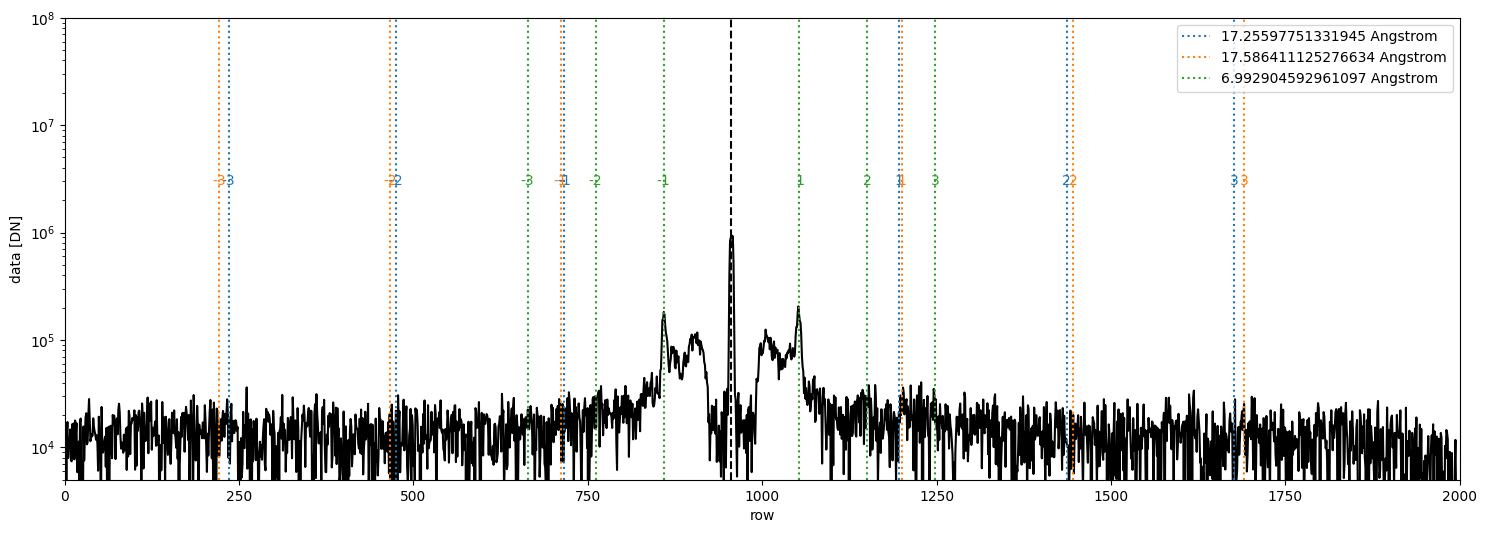

In [50]:
plot_summed_slot_spectra(ds_fe_p1_sub_sum, fe_target_wavelengths[:3], max_order=3, nudge0=0, slot_slice=np.s_[1100:1300])

### Pointing 2

In [52]:
ds_fe_p2 = ds_fe.isel(sample=np.where(ds_fe.time>pointing_changes[1])[0])

In [53]:
ds_fe_p2_sub = pedestal_remove_dark_frames(ds_fe_p2.sel(exposure_time=60000))

In [54]:
ds_fe_p2_sub_sum = ds_fe_p2_sub.sum(dim='sample').compute()

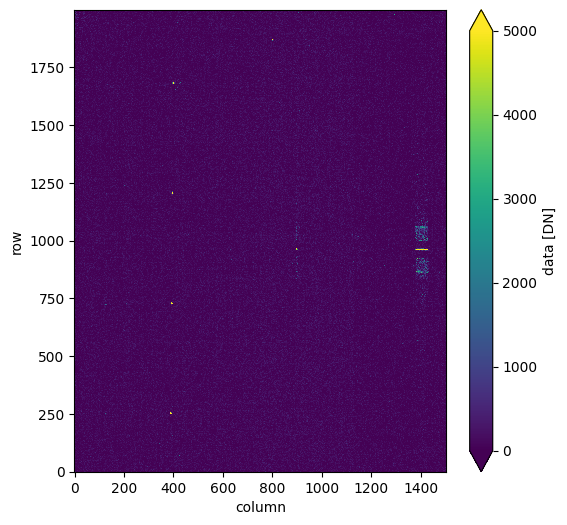

In [55]:
size=6
fig = plt.figure(figsize=(size,size))
ax = fig.add_subplot()
norm = ImageNormalize(vmin=0,vmax=5e3)
ds_fe_p2_sub_sum.plot.imshow(ax=ax, cmap='viridis',norm=norm,interpolation='none')#vmin=2.8e6, vmax=3.1e6,cmap='viridis');

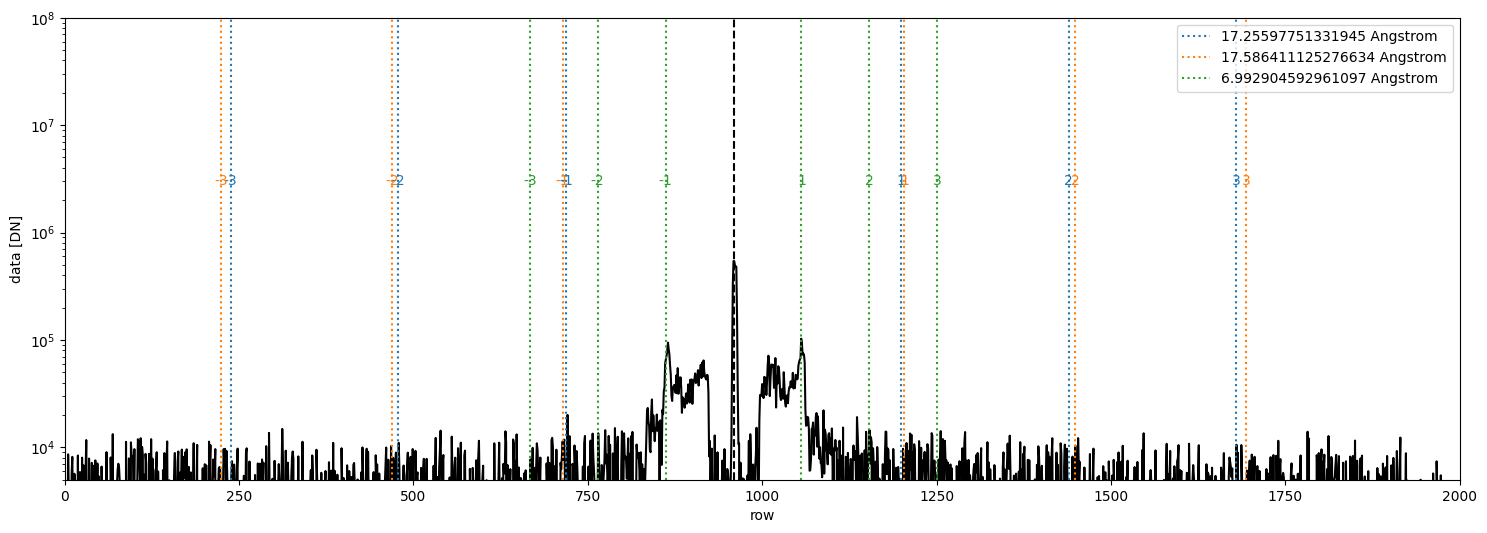

In [57]:
plot_summed_slot_spectra(ds_fe_p2_sub_sum, fe_target_wavelengths[:3], max_order=3, nudge0=0, slot_slice=np.s_[1300:1500])

## Combine pointings?

Poor man's coalignment after slicing over the slot

In [67]:
ds_fe_pall_sub_sum = ds_fe_p0_sub_sum.isel(column=np.s_[1200:1350]) + ds_fe_p1_sub_sum.isel(column=np.s_[1050:1200]) + ds_fe_p2_sub_sum.isel(column=np.s_[1300:1450])

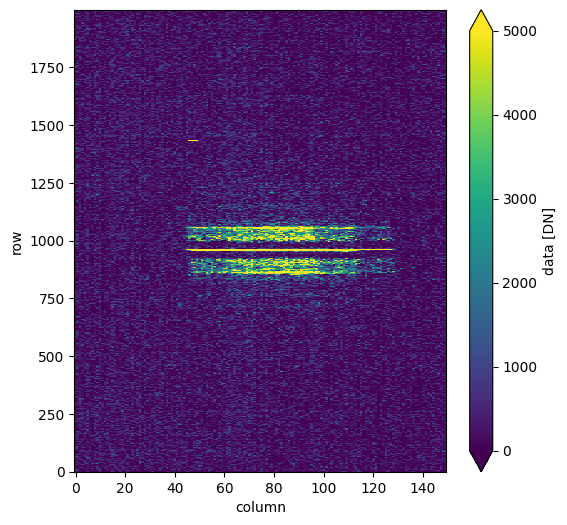

In [68]:
size=6
fig = plt.figure(figsize=(size,size))
ax = fig.add_subplot()
norm = ImageNormalize(vmin=0,vmax=5e3)
ds_fe_pall_sub_sum.plot.imshow(ax=ax, cmap='viridis',norm=norm,interpolation='none')#vmin=2.8e6, vmax=3.1e6,cmap='viridis');

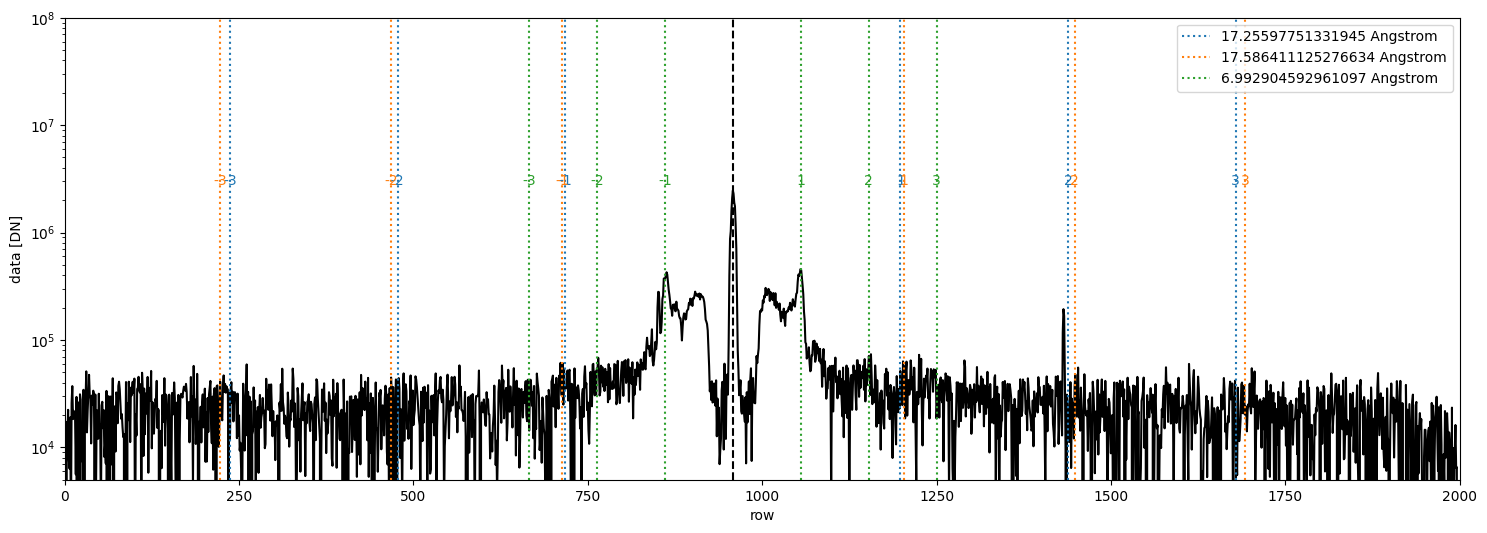

In [70]:
plot_summed_slot_spectra(ds_fe_pall_sub_sum, fe_target_wavelengths[:3], max_order=3, nudge0=0, slot_slice=np.s_[:])

### Higher current Fe data
This is a dataset where we switched to a higher current in an effor to see the Fe L$\alpha$ line

In [100]:
ds_fe_high_current = list_of_files_to_ds_lazy(sorted((data_root_dir / '20261102' / 'higher_current').glob('csie_image*.bin.fits')))

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 528/528 [00:02<00:00, 199.50it/s]


In [101]:
ds_fe_high_current_sub_better = pedestal_remove_dark_frames(ds_fe_high_current.sel(exposure_time=60000))

In [102]:
ds_fe_high_current_sub_better_sum = ds_fe_high_current_sub_better.sum(dim='sample').compute()

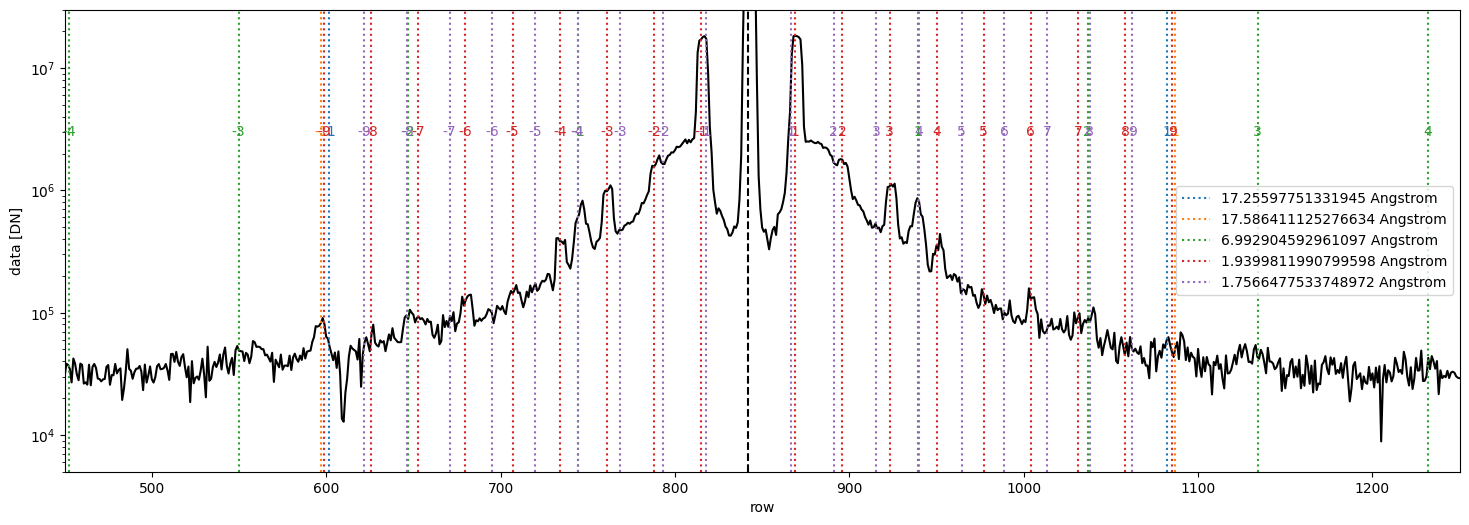

In [105]:
plot_summed_slot_spectra(ds_fe_high_current_sub_better_sum,
                         fe_target_wavelengths,
                         max_order=9,
                         text_ypos=3e6,
                         ylim=(5e3,3e7),
                         xlim=(450,1250))

## Al Data

In [201]:
al_target_files = sorted((data_root_dir / '20261029').glob('csie_image_*.bin.fits'))[:1500]

In [202]:
ds_al = list_of_files_to_ds_lazy(al_target_files)

100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1500/1500 [00:05<00:00, 254.01it/s]


In [211]:
ds_al_sub = pedestal_remove_dark_frames(ds_al.sel(exposure_time=60000))
#ds_al_sub = pedestal_remove_median_short(ds_al.sel(exposure_time=60000))
#ds_al_sub = ds_al.sel(sample=np.s_[:])['data']

In [212]:
ds_al_sub_sum = ds_al_sub.sum(dim='sample').compute()

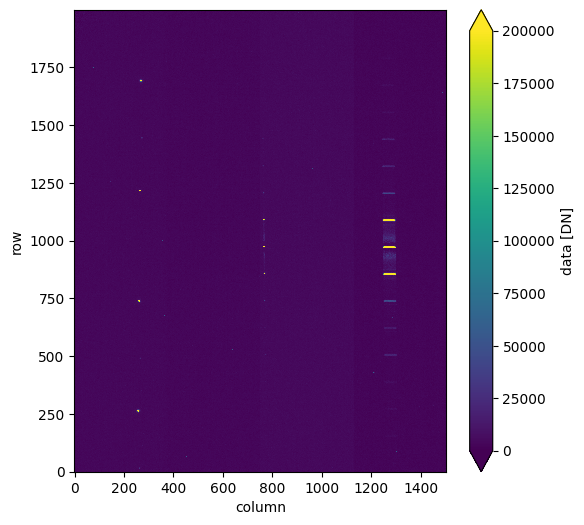

In [213]:
size=6
fig = plt.figure(figsize=(size,size))
ax = fig.add_subplot()
norm = ImageNormalize(vmin=0,vmax=2e5)
ds_al_sub_sum.plot.imshow(ax=ax, cmap='viridis',norm=norm,interpolation='none')#vmin=2.8e6, vmax=3.1e6,cmap='viridis');

The background subtraction doesn't seem to work that well here...

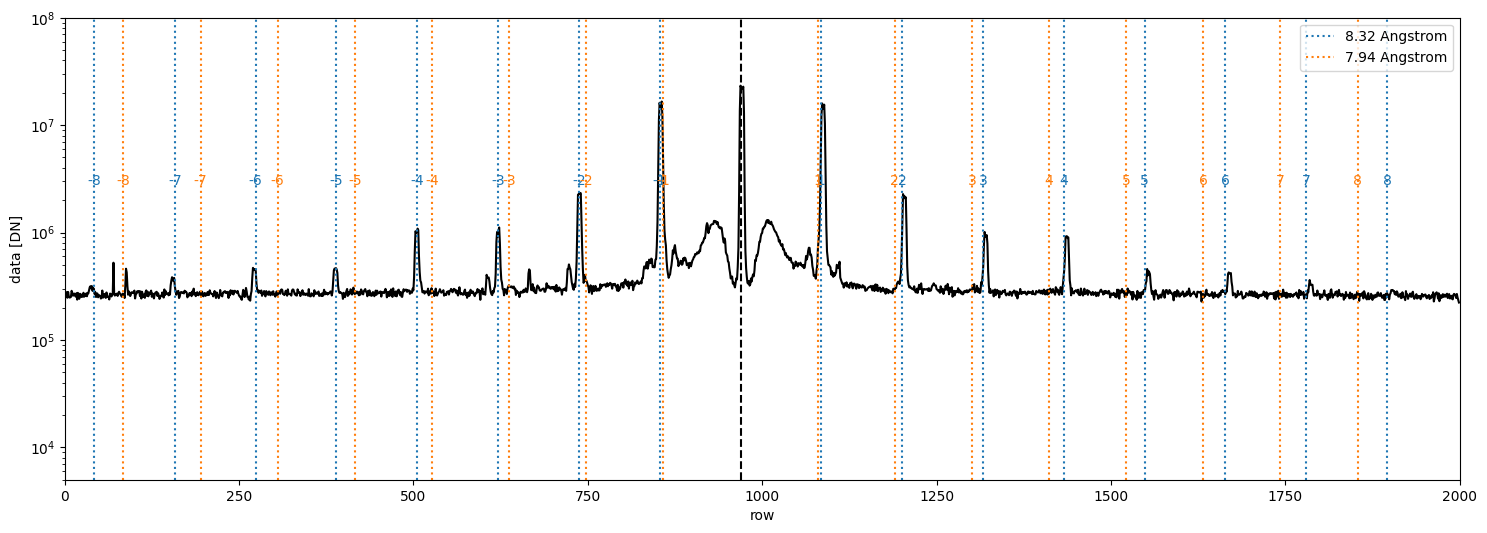

In [214]:
plot_summed_slot_spectra(ds_al_sub_sum, psa_target_table[2:4]['Wavelength'], max_order=8, )

## Cu Data

In [104]:
cu_target_files = sorted((data_root_dir / '20261103').glob('csie_image_*.bin.fits'))

In [105]:
ds_cu = list_of_files_to_ds_lazy(cu_target_files)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 505/505 [00:03<00:00, 164.72it/s]


In [88]:
ds_cu_sub_better = pedestal_remove_dark_frames(ds_cu.sel(exposure_time=60000))

In [89]:
ds_cu_sub_better_sum = ds_cu_sub_better.sum(dim='sample').compute()

In [112]:
ds_cu_sub = ds_cu['data'].sel(exposure_time=5000) - pedestal_func(ds_cu.sel(exposure_time=5000),ped_coeffs)#pedestal_remove_median_short(ds_cuds.sel(exposure_time=60000))

In [113]:
ds_cu_sub_sum = ds_cu_sub.sum(dim='sample').compute()

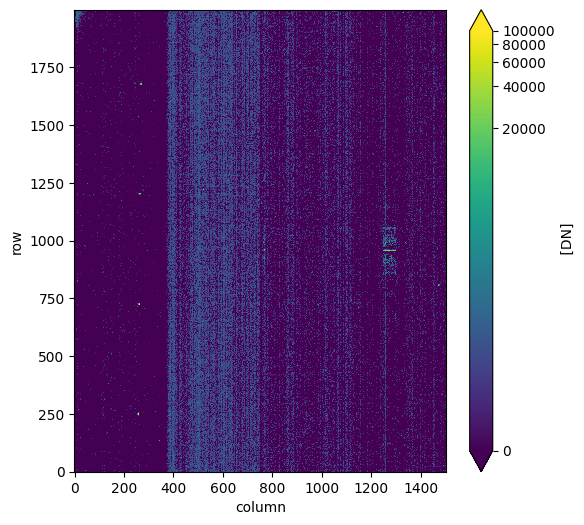

In [114]:
size = 6
fig = plt.figure(figsize=(size,size))
ax = fig.add_subplot()
norm = ImageNormalize(vmin=0,vmax=1e5, stretch=LogStretch())
ds_cu_sub_sum.plot.imshow(ax=ax,
                          cmap='viridis',
                          norm=norm,
                          interpolation='none')#vmin=2.8e6, vmax=3.1e6,cmap='viridis');

In [115]:
cu_target_wavelengths = [1.55,7,13.32]*u.AA

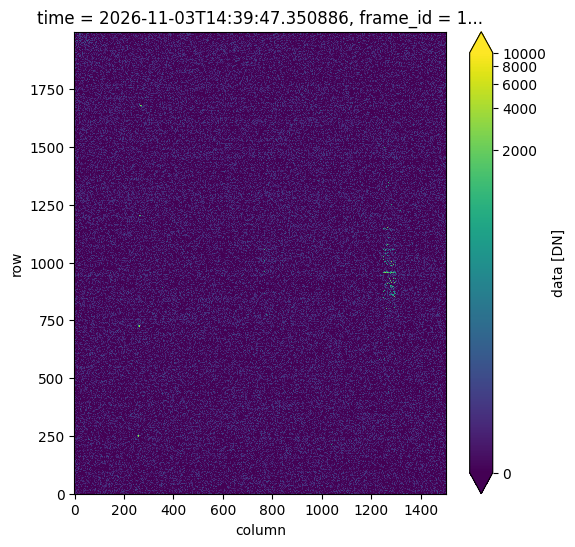

In [34]:
size = 6
fig = plt.figure(figsize=(size,size))
ax = fig.add_subplot()
norm = ImageNormalize(vmin=0,vmax=1e4, stretch=LogStretch())
ds_cu_sub_better.isel(sample=0).plot.imshow(ax=ax,
                          cmap='viridis',
                          norm=norm,
                          interpolation='none')
#plt.xlim(1240,1320)

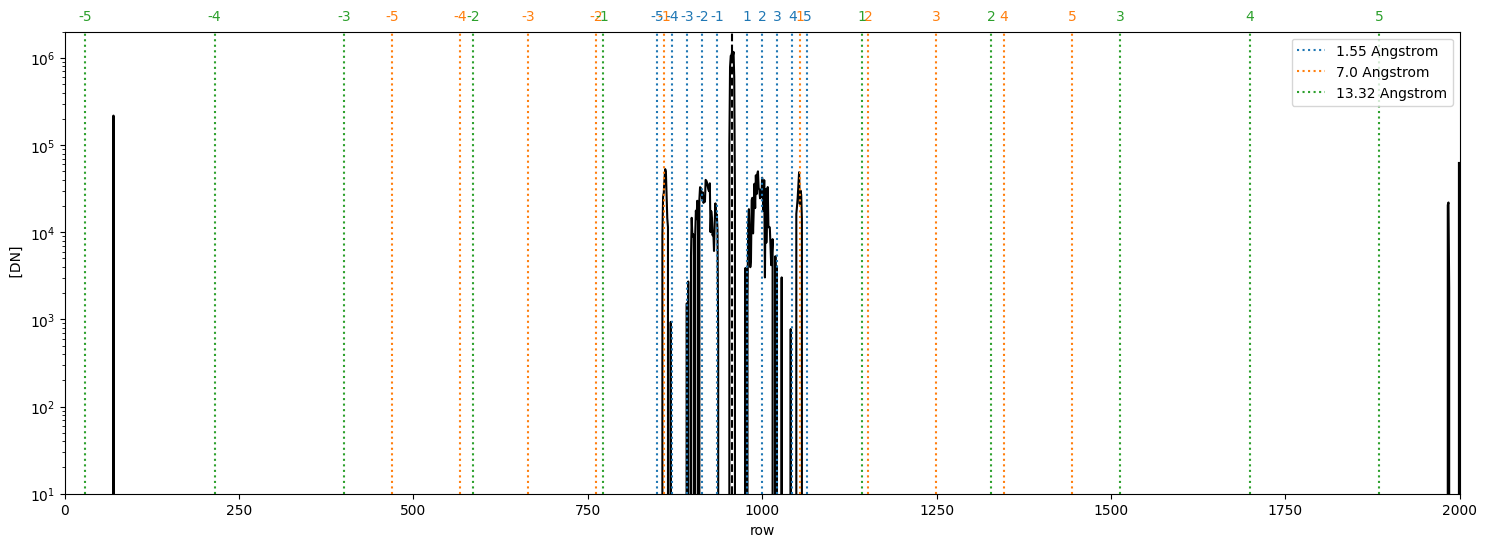

In [118]:
plot_summed_slot_spectra(ds_cu_sub_sum, cu_target_wavelengths, max_order=5, text_ypos=3e6, ylim=(1e1,2e6))

## Dust Grain Hunting

In [57]:
ds_dust_hunting = list_of_files_to_ds_lazy(
    sorted((data_root_dir / '20261103' / 'dust_hunting').glob('csie_image*.bin.fits'))
)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 280/280 [00:01<00:00, 246.16it/s]


In [58]:
ds_dust_hunting_sub = pedestal_remove_dark_frames(ds_dust_hunting)

In [65]:
ds_dust_hunting_sub_summed = ds_dust_hunting_sub.sum(dim='sample')

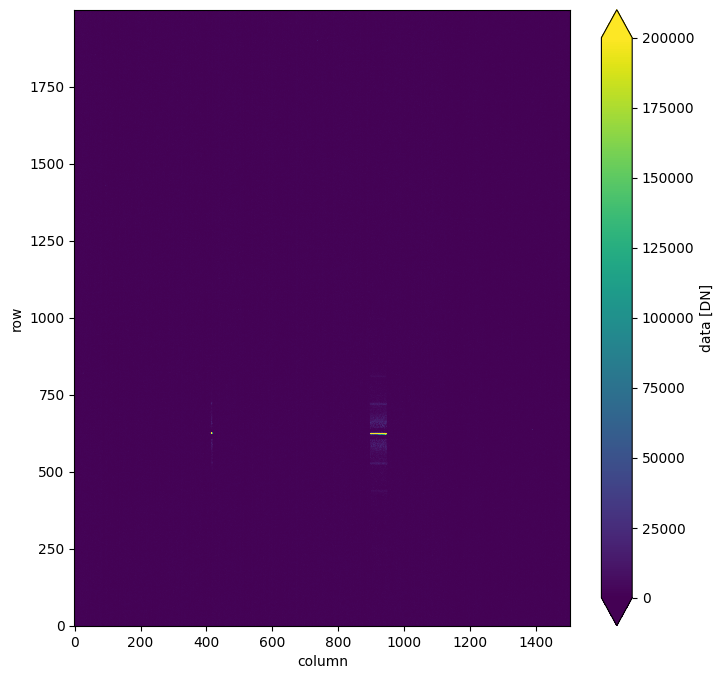

In [66]:
fig = plt.figure(figsize=(8,8))
norm = ImageNormalize(vmin=0,vmax=2e5)
ds_dust_hunting_sub_summed.plot.imshow(cmap='viridis',norm=norm)
#plt.ylim(250,550)
#plt.xlim(800,1100)

(700.0, 1100.0)

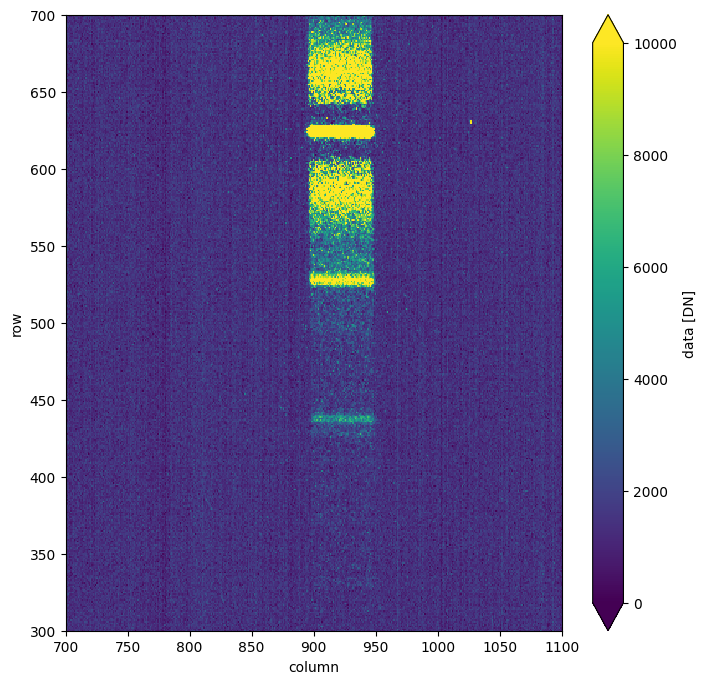

In [81]:
fig = plt.figure(figsize=(8,8))
norm = ImageNormalize(vmin=0,vmax=1e4)
ds_dust_hunting_sub_summed.plot.imshow(cmap='viridis',norm=norm)
plt.ylim(300,700)
plt.xlim(700,1100)

(875.0, 975.0)

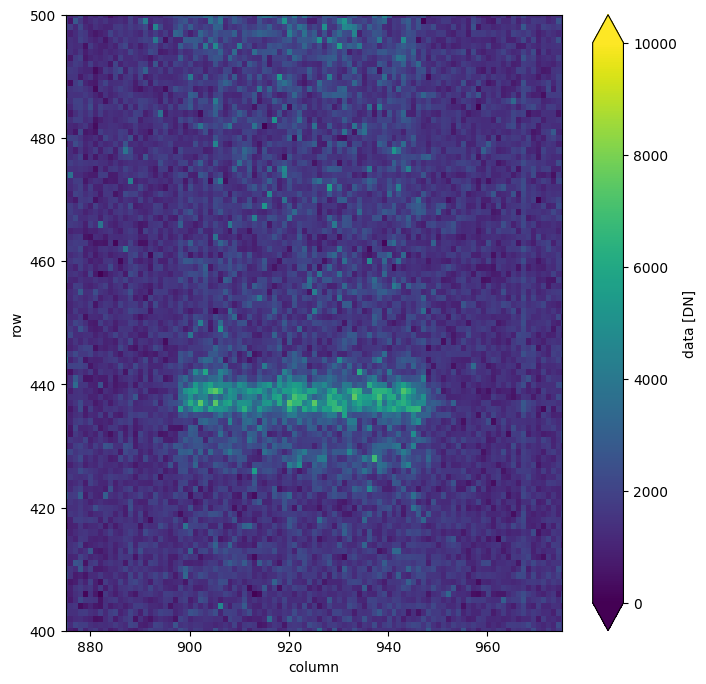

In [82]:
fig = plt.figure(figsize=(8,8))
norm = ImageNormalize(vmin=0,vmax=1e4)
ds_dust_hunting_sub_summed.plot.imshow(cmap='viridis',norm=norm)
plt.ylim(400,500)
plt.xlim(875,975)

(80000.0, 1000000.0)

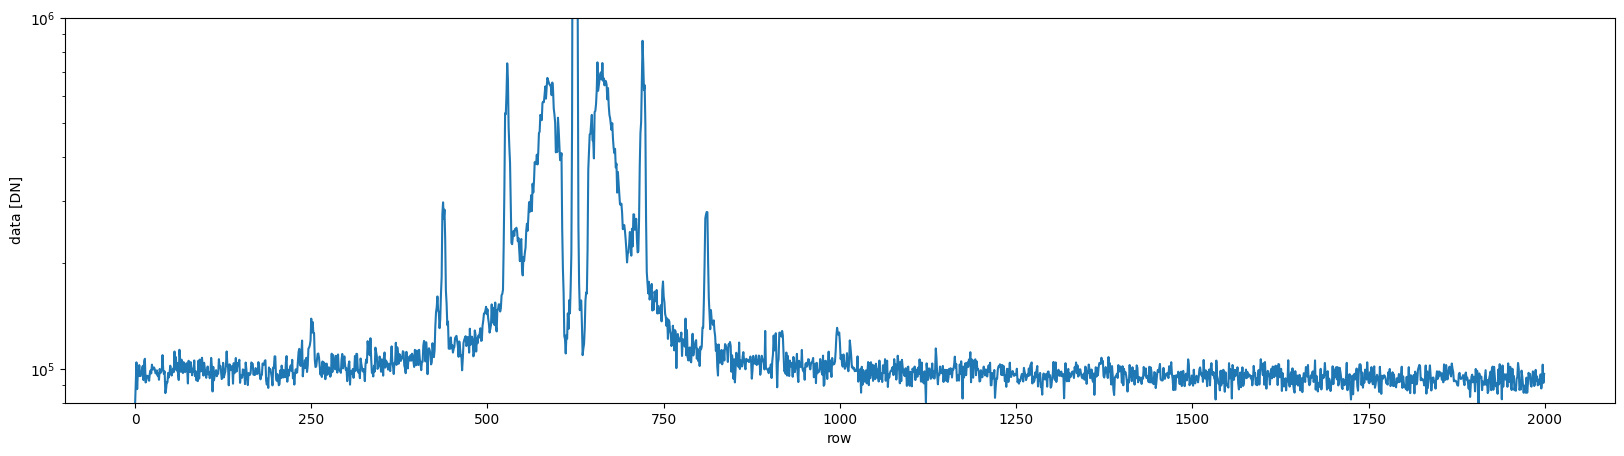

In [80]:
plt.figure(figsize=(20,5))
ds_dust_hunting_sub_summed.sel(column=np.s_[890:960]).sum(dim='column').plot()
plt.yscale('log')
#plt.xlim(250,500)
plt.ylim(8e4,1e6)

## C Target

In [231]:
c_target_files = sorted((data_root_dir / '20261104').glob('csie_image_*.bin.fits'))

Task was destroyed but it is pending!
task: <Task pending name='Task-1779' coro=<_async_in_context.<locals>.run_in_context() done, defined at /Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-1780' coro=<Kernel.shell_main() running at /Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/zmq/eventloop/zmqstream.py:563]>
/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/pathlib/_local.py:128: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  path = os.fspath(arg)
Task was destroyed but it is pending!
task: <Task pending name='Task-1780' coro=<Kernel.shell_main() running at /Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/ipykernel/kernelbase.py:597> cb=[T

In [232]:
ds_c = list_of_files_to_ds_lazy(c_target_files)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 566/566 [00:03<00:00, 185.05it/s]


In [233]:
ds_c_highc = ds_c.isel(sample=np.where(ds_c.time>ds_c.time[304].data)[0]).sel(exposure_time=60000)

In [236]:
#ds_c_sub_better = pedestal_remove_dark_frames(ds_c.sel(exposure_time=60000), ds_dark_frames_20261104)
ds_c_sub_better = ds_c_highc['data'] - ds_c_highc.median(dim='sample')['data']

In [237]:
ds_c_sub_better_thresh = xarray.where(ds_c_sub_better>50, ds_c_sub_better,0)
ds_c_sub_better_sum = ds_c_sub_better_thresh.sum(dim='sample').compute()

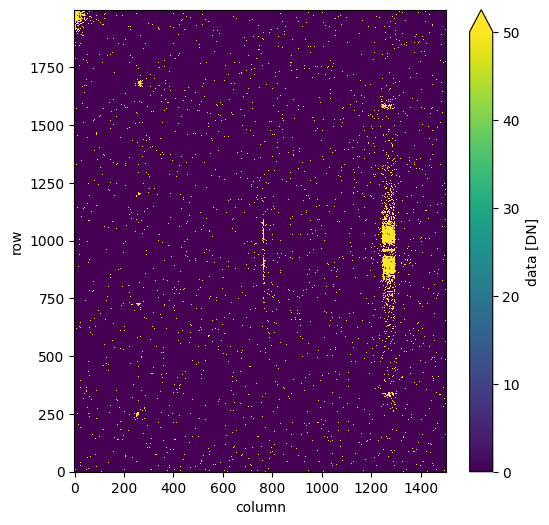

In [243]:
size = 6
fig = plt.figure(figsize=(size,size))
ax = fig.add_subplot()
norm = ImageNormalize(vmin=0,vmax=5e1)
ds_c_sub_better_sum.plot.imshow(ax=ax,
                                cmap='viridis',
                                norm=norm,
                                interpolation='none')
#plt.xlim(1220,1310)

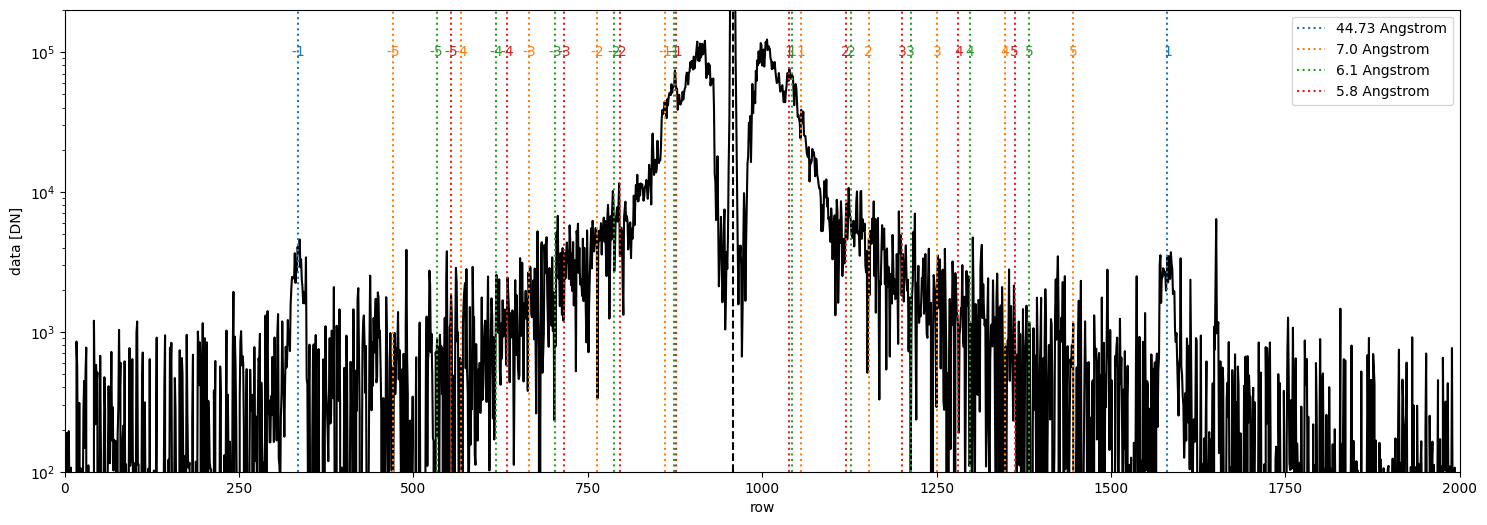

In [245]:
plot_summed_slot_spectra(ds_c_sub_better_sum,
                         np.append(np.append(psa_target_table[[0,-1]]['Wavelength'], 6.1*u.AA),5.8*u.AA),
                         max_order=5,
                         text_ypos=1e5,
                         ylim=(1e2,2e5),
                         slot_slice=np.s_[1220:1310],
                         nudge0=2)

## Ag Target

In [246]:
ag_target_files = sorted((data_root_dir / '20261104' / 'silver_target').glob('csie_image_*.bin.fits'))

In [247]:
ds_ag = list_of_files_to_ds_lazy(ag_target_files)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 567/567 [00:02<00:00, 195.84it/s]


In [248]:
ds_ag = ds_ag.sel(exposure_time=60000)

In [263]:
ds_ag_sub_better = pedestal_remove_dark_frames(ds_ag.sel(exposure_time=60000), ds_dark_frames_20261104)
#ds_ag_sub_better = ds_ag['data'] - ds_ag.median(dim='sample')['data']

In [264]:
ds_ag_sub_better_thresh = xarray.where(ds_ag_sub_better>50, ds_ag_sub_better,0)
ds_ag_sub_better_sum = ds_ag_sub_better_thresh.sum(dim='sample').compute()

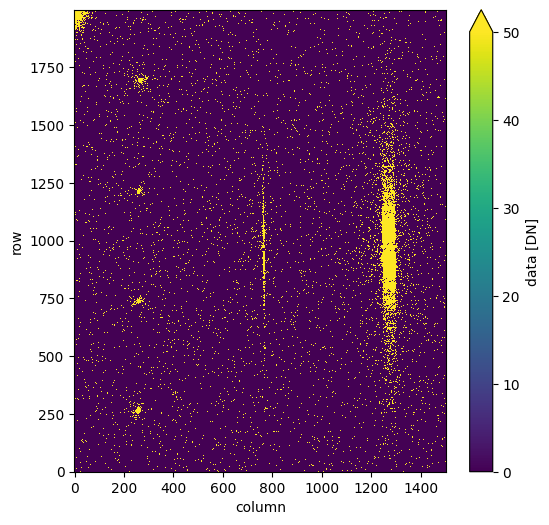

In [265]:
size = 6
fig = plt.figure(figsize=(size,size))
ax = fig.add_subplot()
norm = ImageNormalize(vmin=0,vmax=5e1)
ds_ag_sub_better_sum.plot.imshow(ax=ax,
                                cmap='viridis',
                                norm=norm,
                                interpolation='none')
#plt.xlim(1220,1310)

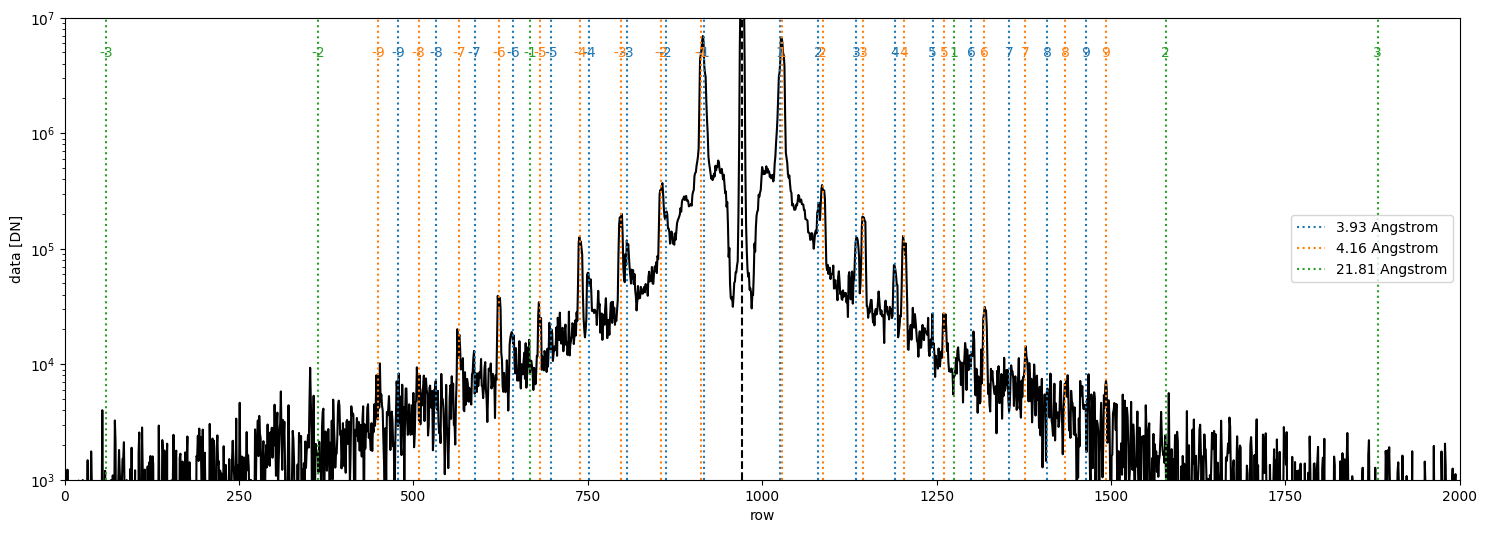

In [273]:
plot_summed_slot_spectra(ds_ag_sub_better_sum,
                         #np.append(np.append(psa_target_table[[0,-1]]['Wavelength'], 6.1*u.AA),5.8*u.AA),
                         psa_target_table[psa_target_table['Element']=='Ag']['Wavelength'][[3,2,5]],
                         max_order=9,
                         text_ypos=5e6,
                         ylim=(1e3,1e7),
                         slot_slice=np.s_[1220:1310],
                         nudge0=-2)

In [275]:
ds_ag_sub_better_thresh[0].plot.imshow

<xarray.DataArray 'data' (row: 2000, column: 1504)> Size: 24MB
dask.array<getitem, shape=(2000, 1504), dtype=float64, chunksize=(1818, 1367), chunktype=numpy.ndarray>
Coordinates:
    time                    datetime64[us] 8B 2026-11-05T01:35:01.461193
    frame_id                int64 8B 155181
    temperature_detector_0  float64 8B -32.94
    temperature_detector_1  float64 8B -31.22
    temperature_adc         float64 8B 22.88
    temperature_fpga        float64 8B 28.07
    exposure_time           int64 8B 60000
Dimensions without coordinates: row, column
Attributes:
    unit:     DN

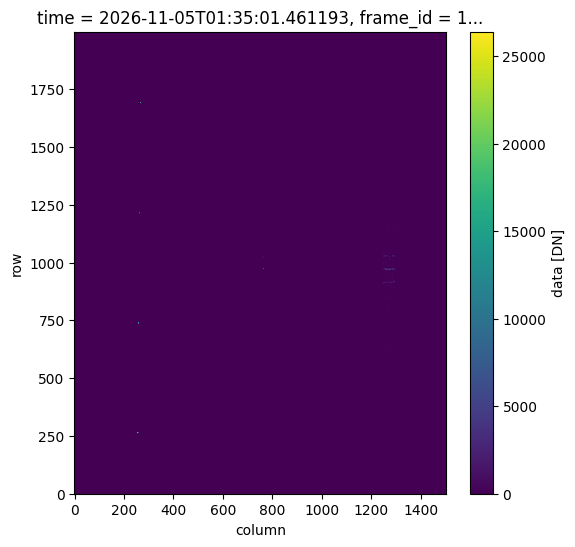

In [287]:
size = 6
fig = plt.figure(figsize=(size,size))
ax = fig.add_subplot()
norm = ImageNormalize(vmin=0,)
ds_ag_sub_better_thresh[0].plot.imshow(ax=ax,
                                       cmap='viridis',
                                       norm=norm,
                                       interpolation='none')
#plt.xlim(240,280)
#plt.ylim(240,280)

In [ ]:
moxsi

In [297]:
zerod_frame = xarray.where(xarray.dot(ds_ag_sub_better.row<280, ds_ag_sub_better.column<280), ds_ag_sub_better_thresh[0], 0)

In [302]:
idx_max = np.unravel_index(zerod_frame.argmax(),zerod_frame.shape)

/Users/wtbarnes/miniforge3/envs/moxsi-science/lib/python3.13/site-packages/xarray/core/dataarray.py:6386: FutureWarning: Behaviour of argmin/argmax with neither dim nor axis argument will change to return a dict of indices of each dimension. To get a single, flat index, please use np.argmin(da.data) or np.argmax(da.data) instead of da.argmin() or da.argmax().
  result = self.variable.argmax(dim, axis, keep_attrs, skipna)


In [311]:
earth_observer = get_earth('2020-01-01')
ref_coord = SkyCoord(0, 0, unit='arcsec', frame=Helioprojective(observer=earth_observer))
moxsi_built_filtergrams[0].get_wcs(earth_observer).array_index_to_world(*idx_max,0)

  'angstrom' -> 'Angstrom'. [astropy.wcs.wcs]


[<SkyCoord (Helioprojective: obstime=2020-01-01T00:00:00.000, rsun=695700.0 km, observer=<HeliographicStonyhurst Coordinate (obstime=2020-01-01T00:00:00.000, rsun=695700.0 km): (lon, lat, radius) in (deg, deg, m)
     (0., -2.94243301, 1.47098546e+11)>): (Tx, Ty) in arcsec
     (6921.15549472, -2001.95814879)>,
 <SpectralCoord 
    (target: <Helioprojective Coordinate (obstime=2020-01-01T00:00:00.000, rsun=695700.0 km, observer=<HeliographicStonyhurst Coordinate (obstime=2020-01-01T00:00:00.000, rsun=695700.0 km): (lon, lat, radius) in (deg, deg, m)
                 (0., -2.94243301, 1.47098546e+11)>): (Tx, Ty, distance) in (arcsec, arcsec, kpc)
                 (0., 0., 1000.)
              (d_Tx, d_Ty, d_distance) in (arcsec / s, arcsec / s, km / s)
                 (0., 0., 0.)>)
   1.89538462e-09 m>]